## Step 0) Import modules

Import the required modules our notebook

In [29]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error 

## Step 1) Load student performance from CSV

Load the data stored in student_performance_trunk.csv file into a Pandas DataFrame.

Multi-feature linear regression works best when features' data is at a similar scale. The raw data of Previous Scores ranges from 1-100 and Hours Studied from 1-9. In this section we'll load the data and then divide Previous Scores by 10. This results in both Previous Scores and Hours Studied ranging from roughly 1-10. Alternatively, we could have changed Hours Studied to range from 1-100 to achieve the same result.

Note: Change the scale of a column does not impact the correlation or performance of the model.

In [40]:
student_results = pd.read_csv('datasets/student_performance_updated.csv')
student_results['Previous Scores'] /= 10

## Step 2) Investigate the data

Use the head() and describe() methods of Pandas Dataframes to investigate the data. 

include='all' is used to include text based columns.

In [41]:
# Print the first 20 rows of data
print (student_results.head(20))
# Print an overview of the data
print (student_results.describe(include='all'))

    Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0               8              9.9                        Yes            9   
1               6              8.2                         No            4   
2               4              5.1                        Yes            7   
3               5              5.2                        Yes            5   
4               5              7.5                         No            8   
5               5              7.8                         No            9   
6               7              7.3                        Yes            5   
7               3              4.5                        Yes            4   
8               5              7.7                         No            8   
9               7              8.9                         No            4   
10              6              9.1                         No            4   
11              5              7.9                         No   

## Step 3) View Correlation table

Correlation table allows you to view the r (relationship) values of the table.

r values closer to 1 mean a stronger correlation between the two columns.

**Note**: the highest correlations for performance index are Previous Scores and Hours Studied.

In [ ]:
student_results.corr(numeric_only=True)

                                  Hours Studied  Previous Scores  Sleep Hours  \
Hours Studied                          1.000000         0.833526    -0.151904   
Previous Scores                        0.833526         1.000000    -0.054697   
Sleep Hours                           -0.151904        -0.054697     1.000000   
Sample Question Papers Practiced       0.017226         0.048812    -0.016740   
Performance Index                      0.769259         0.914700    -0.022805   

                                  Sample Question Papers Practiced  \
Hours Studied                                             0.017226   
Previous Scores                                           0.048812   
Sleep Hours                                              -0.016740   
Sample Question Papers Practiced                          1.000000   
Performance Index                                         0.073857   

                                  Performance Index  
Hours Studied                         

## Step 4) Extract features, label and visualise

For this notebook we'll use 2 features, previous scores ad hours studied to predict the performance index.

In [48]:
x_series = student_results[['Previous Scores', 'Hours Studied']]
y_series = student_results['Performance Index']

Now let's visualise it

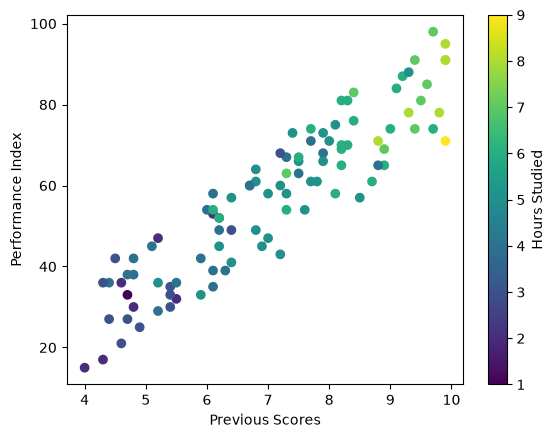

In [49]:
scatter = plt.scatter(x_series['Previous Scores'], y_series, c=x_series['Hours Studied'])
plt.xlabel('Previous Scores')
plt.ylabel('Performance Index')
plt.colorbar(label='Hours Studied')
plt.show()

## Step 5) Train the model

Let's train a Linear Regression model with our 2 features.

In [50]:
model = LinearRegression()

model.fit(x_series, y_series)

model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[10.4 , 0.26]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Previous Scores','Hours Studied']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-17.76
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


## Step 6) Predict a single new value

To test our model, let's have it predict a new performance index. Change the number in the square braces [ ] and view the output. 

In [54]:
new_data = pd.DataFrame({
    'Previous Scores': [6.7],
    'Hours Studied': [5]
})
print ( model.predict(new_data) )

[53.24379671]


## Step 7) View the slope and bias

As part of creating the linear regression model, sklearn as determined our best fit slope (intercept) and biases (weights). Let's see what they are.

In [55]:
slope = model.coef_
bias = model.intercept_

print (f"Slope: {slope}")
print (f"Bias: {bias}")

Slope: [10.39959491  0.26441971]
Bias: -17.755587735797235


## Step 8) Predict label values

Calculate all the performance index values based on our model. Feeding it just the previous scores.

In [59]:
predictions = model.predict(x_series)

Now visualise predicted values vs actual values.

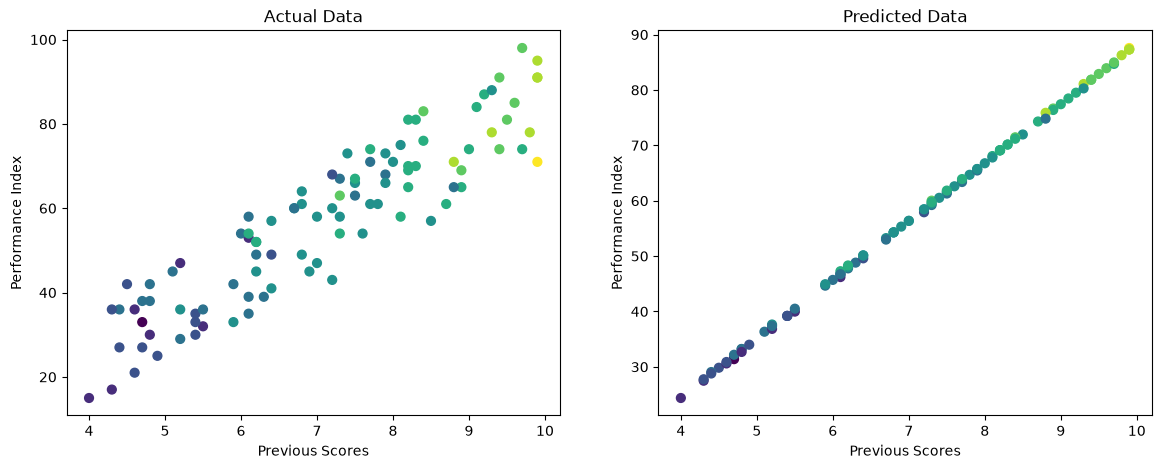

In [61]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(student_results['Previous Scores'], student_results['Performance Index'], c=student_results['Hours Studied'],  s=40)
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Previous Scores")
axs[0].set_ylabel("Performance Index")


axs[1].scatter(student_results['Previous Scores'], predictions, c=student_results['Hours Studied'], s=40)
axs[1].set_title("Predicted Data")
axs[1].set_xlabel("Previous Scores")
axs[1].set_ylabel("Performance Index")

plt.show()

## Step 9) Evaluate the model's overall performance

To calculate the model's performance, we'll look at it's overall score, MAE and MSE. 

Score = 0 to 1. Higher values indicate a more acurate model\
MAE: Mean Absolute Error. Average loss of all predictions\
MSE: Mean Squared Error. Average squared loss of all predictions 

In [62]:
score = model.score(x_series, y_series)
mae = mean_absolute_error(y_true=y_series,y_pred=predictions)
mse = mean_squared_error(y_true=y_series,y_pred=predictions)

print (f"Score: {score}")
print (f"MAE: {mae}")
print (f"MSE: {mse}")

Score: 0.8368292172476774
MAE: 6.753707801027914
MSE: 59.88268192832757


## Step 10) Determine Losses

For this final step we'll check the loss for each of our predicted values compared to the original data.

In [63]:
model_loss = pd.DataFrame({
    'Target': y_series,
    'Predicted result': predictions,
    'Loss': abs(model.predict(x_series).round(2) - y_series)**2
})

print (model_loss)

    Target  Predicted result     Loss
0       91         87.315760  13.5424
1       65         69.107609  16.8921
2       45         36.340025  74.9956
3       36         37.644404   2.6896
4       66         61.563473  19.7136
..     ...               ...      ...
95      30         32.691307   7.2361
96      57         50.123918  47.3344
97      81         82.891502   3.5721
98      36         40.499863  20.2500
99      25         33.995686  81.0000

[100 rows x 3 columns]
